# 03 — Random-Forest-MultiLabel-Training

Nutzt `MultiOutputClassifier` (separater Random Forest je Zielspalte) statt des nativen Multi-Output-`RandomForestClassifier`, weil Letzterer nur EINE über alle Labels gemittelte Feature-Importance liefert -- für ein Diagnostik-Projekt, dessen Mehrwert gerade in der Unterscheidung *welches Merkmal treibt welchen Fehlermodus* liegt, ist das unbefriedigend (siehe `docs/implementation_notes.md`).

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import pickle
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier

from src.paths import figure_path, result_path
from src.data import TARGET_COLUMNS, FEATURE_COLUMNS, ENCODED_TYPE_COLUMNS
from src.train import evaluate_sklearn_classifier
from src.visualize import draw_rf_architecture

## 1. Daten laden

In [2]:
train_df = pd.read_csv("../data/processed/train.csv")
val_df = pd.read_csv("../data/processed/val.csv")
test_df = pd.read_csv("../data/processed/test.csv")

# X als DataFrame (nicht .values) übergeben, damit die Spaltennamen erhalten
# bleiben -- vermeidet eine sklearn-Warnung bei der späteren Inferenz in app.py
feature_cols = FEATURE_COLUMNS + ENCODED_TYPE_COLUMNS
X_train, y_train = train_df[feature_cols], train_df[TARGET_COLUMNS].values
X_val, y_val = val_df[feature_cols], val_df[TARGET_COLUMNS].values
X_test, y_test = test_df[feature_cols], test_df[TARGET_COLUMNS].values

## 2. Training

300 Bäume je Label, `class_weight="balanced_subsample"` gegen das Klassenungleichgewicht.

In [3]:
base_rf = RandomForestClassifier(
    n_estimators=300, class_weight="balanced_subsample", random_state=42, n_jobs=-1
)
# MultiOutputClassifier ruft base_rf.fit() intern 4x auf, einmal je Spalte von y_train
rf = MultiOutputClassifier(base_rf, n_jobs=-1)
rf.fit(X_train, y_train)
print("4 separate Random Forests trainiert.")

4 separate Random Forests trainiert.


## 3. Evaluation auf dem Testset (Standard-Schwelle 0,5)

In [4]:
result = evaluate_sklearn_classifier(rf, X_test, y_test, threshold=0.5)
result["metrics"]

,threshold,precision,recall,f1,roc_auc,pr_auc,n_positive,tn,fp,fn,tp
label,,,,,,,,,,,
TWF,0.5,0.000000,0.000000,0.000000,0.958712,0.055156,7,1493,0,7,0
HDF,0.5,1.000000,0.941176,0.969697,1.000000,1.000000,17,1483,0,1,16
PWF,0.5,1.000000,1.000000,1.000000,1.000000,1.000000,14,1486,0,0,14
OSF,0.5,0.909091,0.666667,0.769231,0.998316,0.892604,15,1484,1,5,10


## 4. Feature Importances je Label

Dank `MultiOutputClassifier` hat jedes Label seinen eigenen, unabhängig trainierten Random Forest mit eigener Feature-Importance-Verteilung.

In [5]:
# rf.estimators_ ist eine Liste von 4 einzeln trainierten RandomForestClassifier-
# Objekten (ein Modell je Zielspalte, in derselben Reihenfolge wie TARGET_COLUMNS)
importances_df = pd.DataFrame(
    {col: est.feature_importances_ for col, est in zip(TARGET_COLUMNS, rf.estimators_)},
    index=feature_cols,
)
importances_df.round(3)

,TWF,HDF,PWF,OSF
Air temperature [K],0.044,0.145,0.007,0.009
Process temperature [K],0.037,0.031,0.009,0.008
Rotational speed [rpm],0.049,0.279,0.181,0.096
Torque [Nm],0.054,0.092,0.316,0.256
Tool wear [min],0.679,0.003,0.011,0.338
Power [W],0.061,0.042,0.465,0.256
Temperature diff [K],0.057,0.407,0.008,0.009
type_H,0.005,0.000,0.001,0.001
type_L,0.005,0.000,0.002,0.019
type_M,0.007,0.000,0.001,0.008


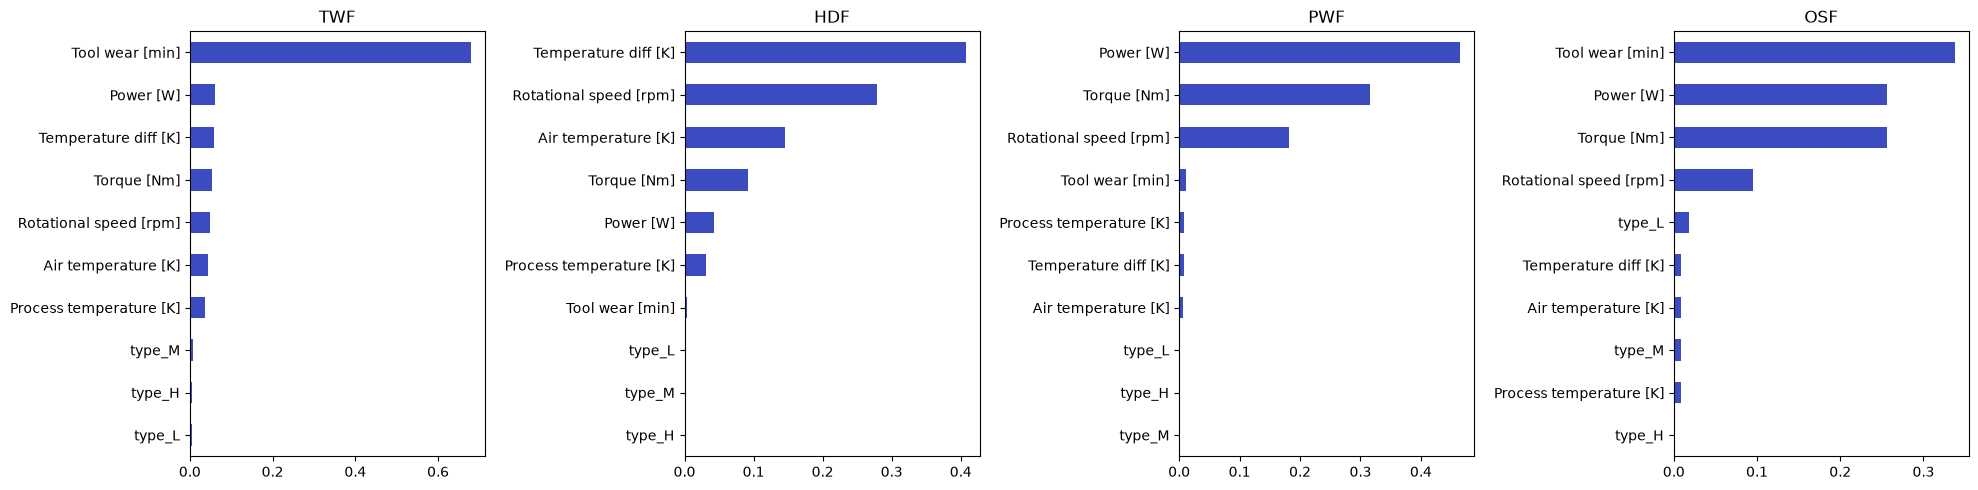

In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, col in zip(axes, TARGET_COLUMNS):
    importances_df[col].sort_values().plot(kind="barh", ax=ax, color="#3b4cc0")
    ax.set_title(col)
plt.tight_layout()
plt.savefig(figure_path("tree", "rf_feature_importances_per_label.png"), dpi=150, bbox_inches="tight")
plt.show()

## 5. Architekturdiagramm

Vier unabhängige Forests, einer je Fehlermodus, mit eigener Wahrscheinlichkeitsausgabe.


In [7]:
draw_rf_architecture(
    output_labels=TARGET_COLUMNS,
    n_trees=rf.estimators_[0].n_estimators,
    n_inputs=len(FEATURE_COLUMNS + ENCODED_TYPE_COLUMNS),
    path=figure_path("tree", "rf_architecture.png"),
)

## 6. Modell + Ergebnisse speichern

In [8]:
result["metrics"].to_csv(result_path("tree", "rf_multilabel_testset_metrics.csv"))
importances_df.to_csv(result_path("tree", "rf_feature_importances_per_label.csv"))

with open("../models/random_forest_multilabel.pkl", "wb") as f:
    pickle.dump(rf, f)

# Val-Wahrscheinlichkeiten für die Schwellenwert-Suche in Notebook 04
val_result = evaluate_sklearn_classifier(rf, X_val, y_val, threshold=0.5)
np.savez("../data/processed/rf_val_probs.npz", y_true=val_result["y_true"], y_prob=val_result["y_prob"])
np.savez("../data/processed/rf_test_probs.npz", y_true=result["y_true"], y_prob=result["y_prob"])
print("Modell + Val-/Test-Wahrscheinlichkeiten + Feature Importances gespeichert.")

Modell + Val-/Test-Wahrscheinlichkeiten + Feature Importances gespeichert.
